# Part 2, Topic 1: Introduction to Voltage Glitching (MAIN)

---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

**SUMMARY:** *Similarly to clock glitching, inserting brief glitches into the power line of an embedded device can result in skipped instructions and corrupted results. Besides providing a more reliable glitch on some targets when compared to clock glitching, voltage glitching also has the advanatage that the Vcc pins on chips are more commonly accessable. This won't be covered in this course, but it can also be used to glitch a device asynchronous to its clock.*

**LEARNING OUTCOMES:**

* Understanding voltage glitch settings
* Building a voltage glitch and crash map.
* Modifying glitch circuit to increase glitch success

## Voltage Glitch Hardware

The ChipWhisperer uses the same hardware block for both voltage and clock glitching, with the only difference being where the glitch output is routed to. Instead of routing to HS2, voltage glitching is performed by routing the glitch to either the `glitch_hp` transistor or the `glitch_lp` transistor. This can be done via the following API calls:

```python
scope.io.glitch_hp = True #enable HP glitch
scope.io.glitch_hp = False #disable LP glitch
scope.io.glitch_lp = True #enable LP glitch
scope.io.glitch_lp = False #disable LP glitch
```

While the hardware block are the same, you'll need to change how it's configued. You wouldn't want to try routing `"clock_xor"` to the glitch transistor and oscillate Vcc like the device's clock! Instead, the following two output settings are best suited to voltage glitching:

1. `"glitch_only"` - insert a glitch for a portion of a clock cycle based on `scope.glitch.width` and `scope.glitch.offset`
1. `"enable_only"` - insert a glitch for an entire clock cycle

Typically, the `"enable_only"` setting will be too powerful for most devices. One situation where it outshines `"glitch_only"` is in glitching asychronous to the target's clock. An example of this is glitching a target with an internal clock. In this case, the ChipWhisperer's clock can be boosted far above the target's to insert a precise glitch, with `repeat` functioning as `width` and `ext_offset` functioning as `offset`.

### Voltage Glitching vs. Clock Glitching

Voltage glitching has some obvious benefits over clock glitching, such as working for a wider varitey of targets, but its downsides are less obvious. One of the biggest is how much it depends on the actual glitch circuit itself. With clock glitching, it's relatively easy to insert a glitch - there's nothing external trying to keep the clock at a certain voltage level. This is very different for a target's power pins. When we try to drop the power pin to ground, there's a lot of stuff fighting us to keep the power pin at the correct voltage, such as decoupling capacitors, bulk supply capacitors, and the voltage regulator supplying the voltage. This means when we make small changes to the glitch circuit, the glitch settings and even our ability to insert a glitch at all completely change! Consider glitching a target on the CW308 UFO board. If you switch your coaxial cable length from 20cm to 40 cm, you'll need to find entirely new glitch settings to repeat the attack (if it's still even possible). This is quite easy to see on an oscilloscope or  using the ChipWhisperer's ADC: longer cables and lower valued shunt resistors will make the glitch less sharp and increase ringing.

While your first thought might be to go for as sharp a glitch as possible, this often won't result in a high glitch success rate. If you're unable to find any working glitches with your current setup, it might be worth changing you hardware setup a bit. For example, on the ChipWhisperer Lite 1 part, you can desolder SJ5 and solder header pins to JP6. Even just connecting these pins with a jumper will have different glitch behaviour than with a soldered SJ5.

You can refer to the training slides for more information about finding good glitch settings, as well as more on the theory side of voltage glitching.

### The Lab

To introduce you to volatge glitching and find some settings, we're going to walk back through the clock glitching loop lab. You may want to capture some power traces while you're first experimenting with glitches to see what effects different glitch widths have on the power trace. Another thing to keep in mind is that targets often won't tolerate the Vcc pin dropping for an extended period of time without crashing - once you see the target start to crash, you won't see much else with larger widths.

One thing you might have to change is the glitch repeat value. Depending on how wide your glitch is, the voltage at the power pin may not recover by the time the next glitch is inserted. This can have to effect of increasing subsequent glitches' strength, which may or may not be desirable. Since glitches inserted with repeat > 1 have different strength, it's a good idea to scan through ext_offset as well.

###  Higher Frequency Glitching

The XMEGA target, and to a lesser extent the STM32F3, is very difficult to glitch with the default ChipWhisperer settings. Try bumping the clock frequency to 24MHz for the STM32 or 32MHz for the XMEGA and use a repeat 5-10 with both the high power and low power glitches active. You'll need to adjust the baud rate by the same proportion as the clock. This will increase the glitch precision, as the glitch width/offset step is based on the target clock, and may decrease the stability of the target.

Another setup that seems to work with the XMEGA is SJ5 unsoldered, JP6 jumpered, high+low power glitch, 32MHz, and repeat=5.

The ChipWhisperer Husky, with its PLL based glitching system, can typically glitch targets without needing to change the target's frequency.

### Disabling Logging

When glitching (or just running normally in earlier labs), you may have seen various warnings from loggers ChipWhisperer uses. This often has useful information, especially if things don't work right, but for voltage 
glitching especially, it mostly clutters up any print output you have. As such, we'll disable logging for the voltage glitching labs:

```python
cw.set_all_log_levels(cw.logging.CRITICAL)
```

You can reenable logging via

```python
cw.set_all_log_levels(cw.logging.WARNING)
```

In [1]:
SCOPETYPE = 'OPENADC'
PLATFORM = 'CW312_SAM4S'
SS_VER = 'SS_VER_2_1'

In [2]:
%run "../../Setup_Scripts/Setup_Generic.ipynb"

INFO: Found ChipWhisperer😍
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen            

In [55]:
scope.errors.clear()          # if this fails, try dir(scope.errors) / dir(scope.adc)
print(scope.adc.errors)

False


In [3]:
%%bash -s "$PLATFORM" "$SS_VER"
cd ../../../firmware/mcu/simpleserial-glitch
make PLATFORM=$1 CRYPTO_TARGET=NONE SS_VER=$2 -j

SS_VER set to SS_VER_2_1
SS_VER set to SS_VER_2_1
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CW312_SAM4S 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
Compiling:
Compiling:
.
Compiling:
-en     simpleserial-glitch.c ...
-en     .././simpleserial/simpleserial.c ...
Compiling:
-en     .././hal/hal.c ...
-en     .././hal//sam4s/startup_sam4s.c ...
.
.
.
Compiling:
.
Compiling:
Compiling:
-en     .././hal//sam4s/sam4s_hal.c ...
.
Compiling:
-en     .././hal//sam4s/uart.c ...
-en     .././hal//sam4s/pio.c ...
Compiling:
-en     .././hal//sam4s/system_sam4s.c ...
-en     .././hal//sam4s/sysclk.c ...
.
Compiling:
-en     .././hal//sam4s/pmc.c ...
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
-e Done!
.
LINKING:
-en  

In [3]:
fw_path = "../../../firmware/mcu/simpleserial-glitch/simpleserial-glitch-{}.hex".format(PLATFORM)
cw.program_target(scope, prog, fw_path)
if SS_VER=="SS_VER_2_1":
    target.reset_comms()

In [4]:
# init - from solution
num_tries = 1 # increase to get better glitch stats
gc = cw.GlitchController(groups=["success", "reset", "normal"], parameters=["width", "offset", "ext_offset", "tries"])
gc.set_range("tries", 1, num_tries)

scope.glitch.output = "glitch_only" # glitch_out = clk ^ glitch
scope.glitch.trigger_src = "ext_single" # glitch only after scope.arm() called

gc.set_range("width", 1850, 3000)
gc.set_range("offset", 1800, 3000)
gc.set_global_step([50]) # reduce to fine tune glitching

gc.set_step("ext_offset", 1)
gc.set_range("ext_offset", 10, 50)
scope.glitch.repeat = 1
scope.adc.lo_gain_errors_disabled = True
scope.adc.clip_errors_disabled = True

scope.glitch.enabled = True
scope.glitch.clk_src = "pll"
scope.io.glitch_hp = False
scope.io.glitch_hp = True
scope.io.glitch_lp = False
scope.io.glitch_lp = False

scope.trigger.triggers = "tio4"   # tio4==trigger tio1==tx tio2==rx SAM4S perspective

gc.set_step("tries", 1)

In [5]:
def reboot_flush():
    reset_target(scope)
    target.flush()

In [56]:
# Work out the trigger line from your own setup
# Your ext_single trigger comes from the trigger pins. Check which pins it uses:
print(scope.trigger.triggers)   # e.g. 'tio4'
print(scope.io.tio1, scope.io.tio2, scope.io.tio3, scope.io.tio4)

tio4
serial_rx serial_tx high_z high_z


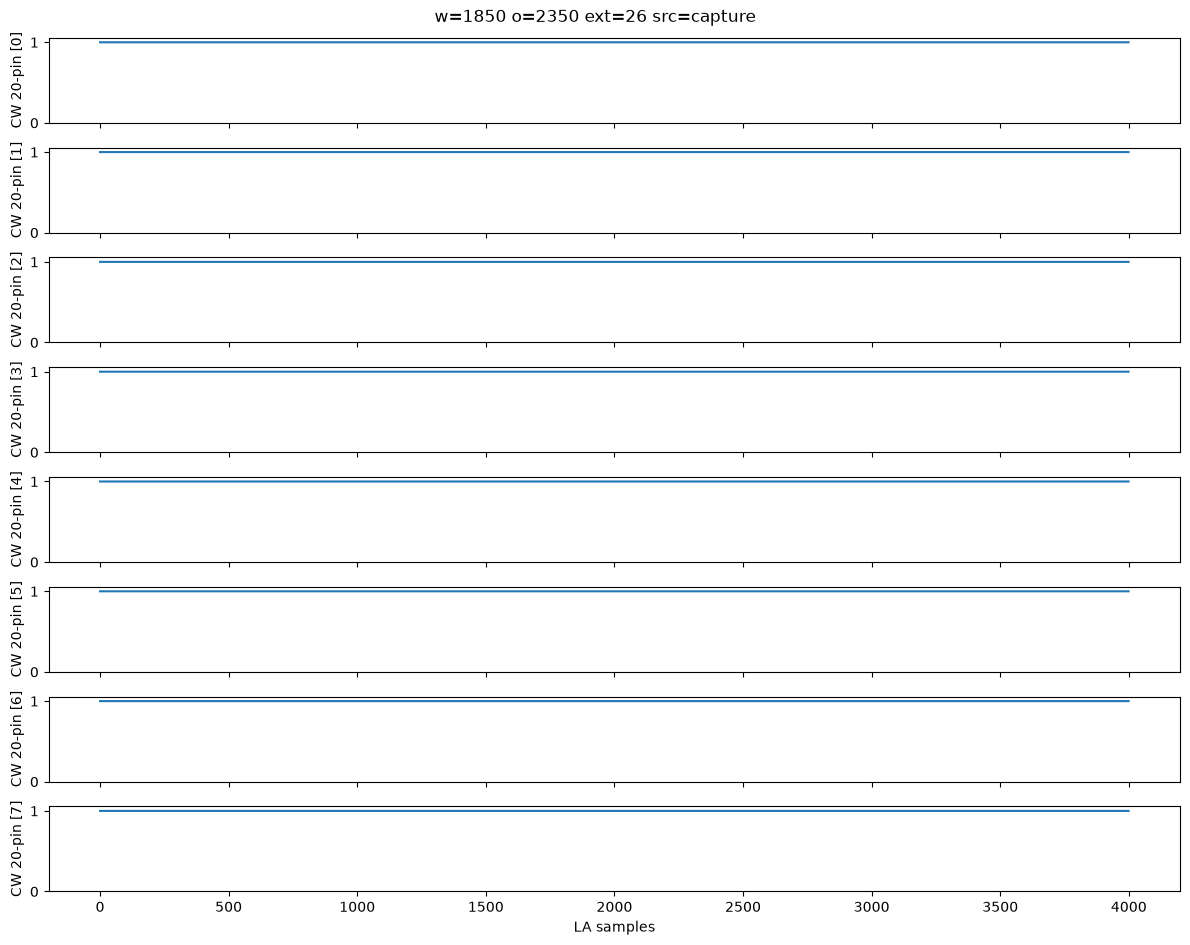

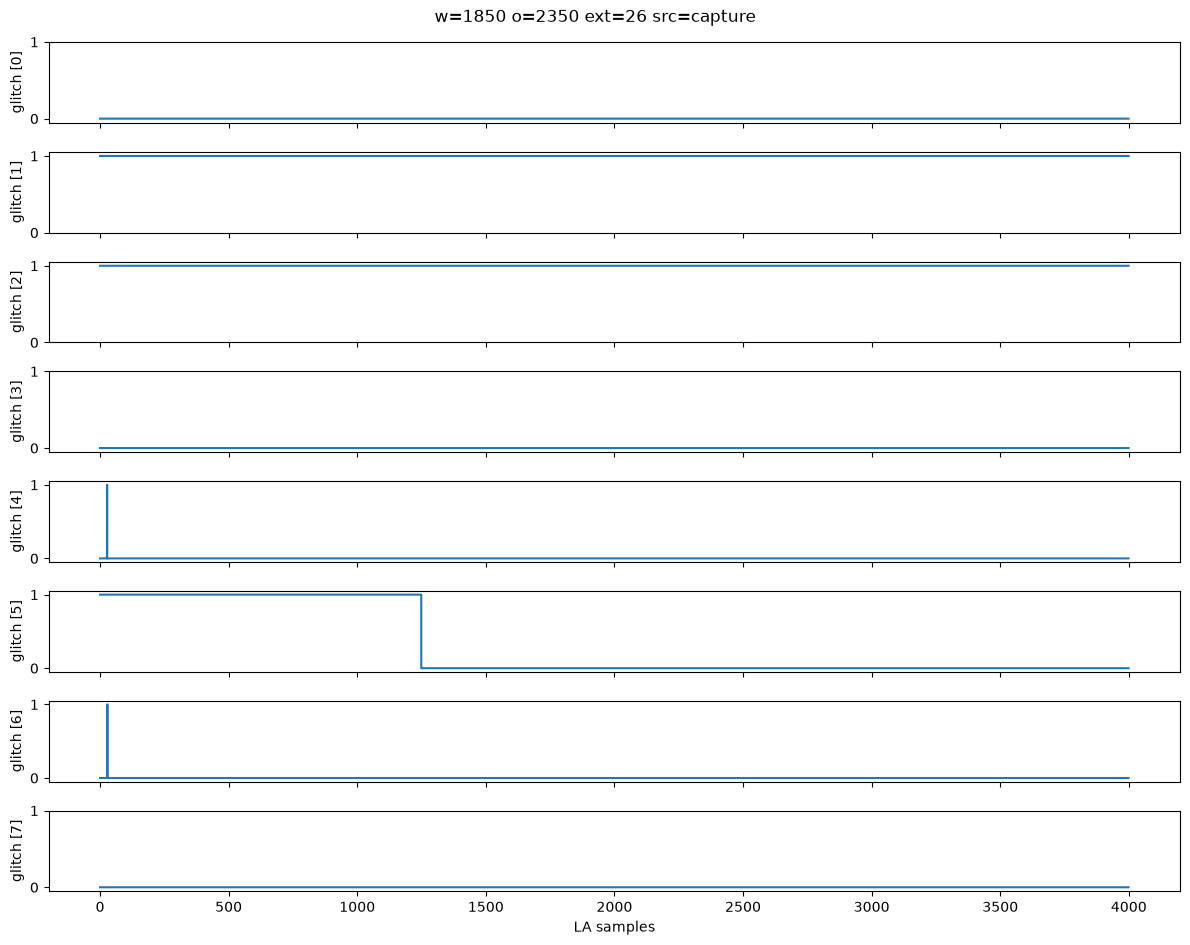

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import struct

    
def visualize_glitch(width, offset, ext_offset, group='CW 20-pin', depth=4000,
                     source='capture'):
    scope.glitch.trigger_src = "ext_single"
    scope.glitch.width = width
    scope.glitch.offset = offset
    scope.glitch.ext_offset = ext_offset

    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = depth
    scope.LA.oversampling_factor = 1
    scope.LA.trigger_source = source

    reboot_flush()
    target.flush()
    scope.LA.arm()          # needed in your build
    scope.arm()
    target.simpleserial_write("g", bytearray([]))
    timed_out = scope.capture()
    scope.io.vglitch_reset()

    if timed_out or scope.LA.fifo_empty():
        print("no data", timed_out, scope.LA.errors)
        scope.LA.enabled = False
        return

    raw = scope.LA.read_capture_data()
    sigs = {}
    for i in range(8):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break
    scope.LA.enabled = False

    fig, axes = plt.subplots(len(sigs), 1, figsize=(12, 1.2 * len(sigs)), sharex=True)
    for ax, (i, s) in zip(np.atleast_1d(axes), sigs.items()):
        ax.step(range(len(s)), s, where='post')
        ax.set_ylabel(f"{group} [{i}]")
        ax.set_yticks([0, 1])
    axes[-1].set_xlabel("LA samples")
    plt.suptitle(f"w={width} o={offset} ext={ext_offset} src={source}")
    plt.tight_layout()
    plt.show()

# use values from a printed success, not whatever the sweep left behind
w, o, e = 0.0, 0.0, 0   # <- replace
w, o, e = scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset
visualize_glitch(w, o, e, group='CW 20-pin')
visualize_glitch(w, o, e, group='glitch')

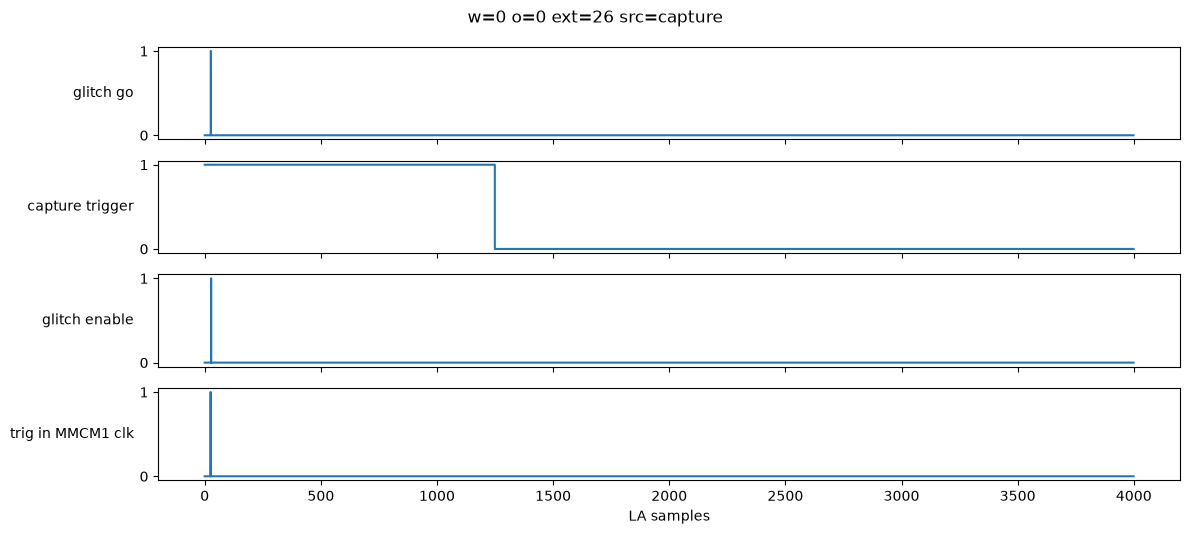

In [95]:
import numpy as np
import matplotlib.pyplot as plt
import struct

NAMES = {
    'glitch': ['glitch output', 'glitch src clock', 'MMCM1 (offset) out',
               'MMCM2 (width) out', 'glitch go', 'capture trigger',
               'glitch enable', 'manual trig (src clk)', 'trig in MMCM1 clk'],
    'CW 20-pin': ['IO1', 'IO2', 'IO3', 'IO4', 'HS1', 'HS2',
                  'AUX MCX', 'TRIG MCX', 'ADC sampling clk'],
}

def plot_la(raw, group, title="", hide_constant=True):
    sigs = {}
    for i in range(9):                       # 9 signals, not 8
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break
    if hide_constant:
        sigs = {i: s for i, s in sigs.items() if s.min() != s.max()}

    fig, axes = plt.subplots(len(sigs), 1, figsize=(12, 1.1 * len(sigs) + 1), sharex=True)
    for ax, (i, s) in zip(np.atleast_1d(axes), sigs.items()):
        ax.step(range(len(s)), s, where='post')
        ax.set_ylabel(NAMES[group][i], rotation=0, ha='right', va='center')
        ax.set_yticks([0, 1])
    axes[-1].set_xlabel("LA samples")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
    
def visualize_glitch(width, offset, ext_offset, group='CW 20-pin', depth=4000,
                     source='capture'):
    scope.glitch.trigger_src = "ext_single"
    scope.glitch.width = width
    scope.glitch.offset = offset
    scope.glitch.ext_offset = ext_offset

    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = depth
    scope.LA.oversampling_factor = 1
    scope.LA.trigger_source = source

    reboot_flush()
    target.flush()
    scope.LA.arm()          # needed in your build
    scope.arm()
    target.simpleserial_write("g", bytearray([]))
    timed_out = scope.capture()
    scope.io.vglitch_reset()

    if timed_out or scope.LA.fifo_empty():
        print("no data", timed_out, scope.LA.errors)
        scope.LA.enabled = False
        return

    raw = scope.LA.read_capture_data()
    sigs = {}
    for i in range(8):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break
    scope.LA.enabled = False
    plot_la(raw, group, f"w={width} o={offset} ext={ext_offset} src={source}")
    

w, o, e = scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset
visualize_glitch(w, o, e, group='glitch')

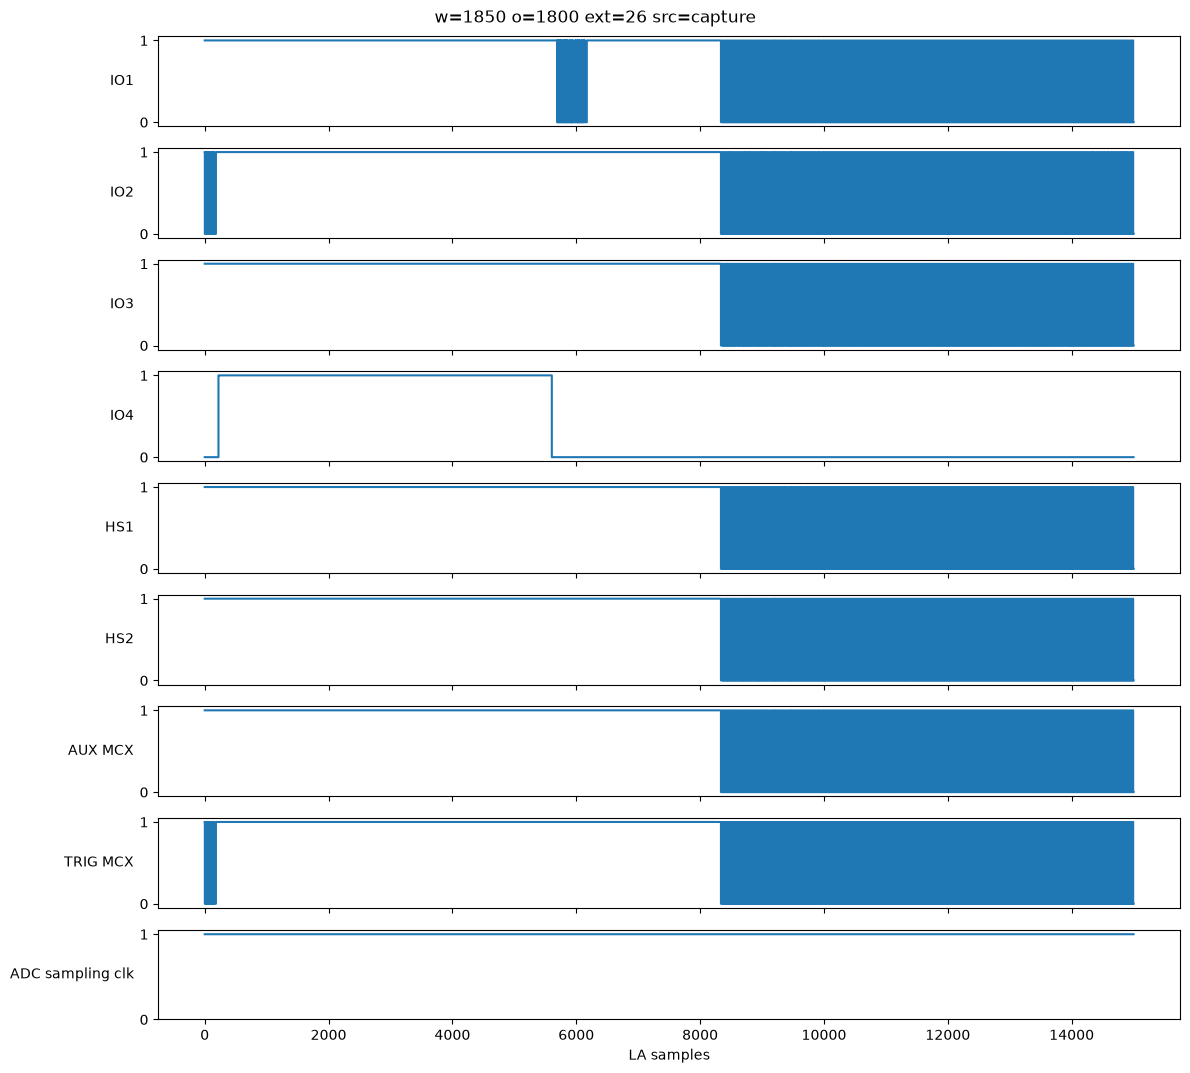

time_axis 1.358002243099103 us
IO4 high for 5383 samples = 7310.13 us (+/- 1.36 us)


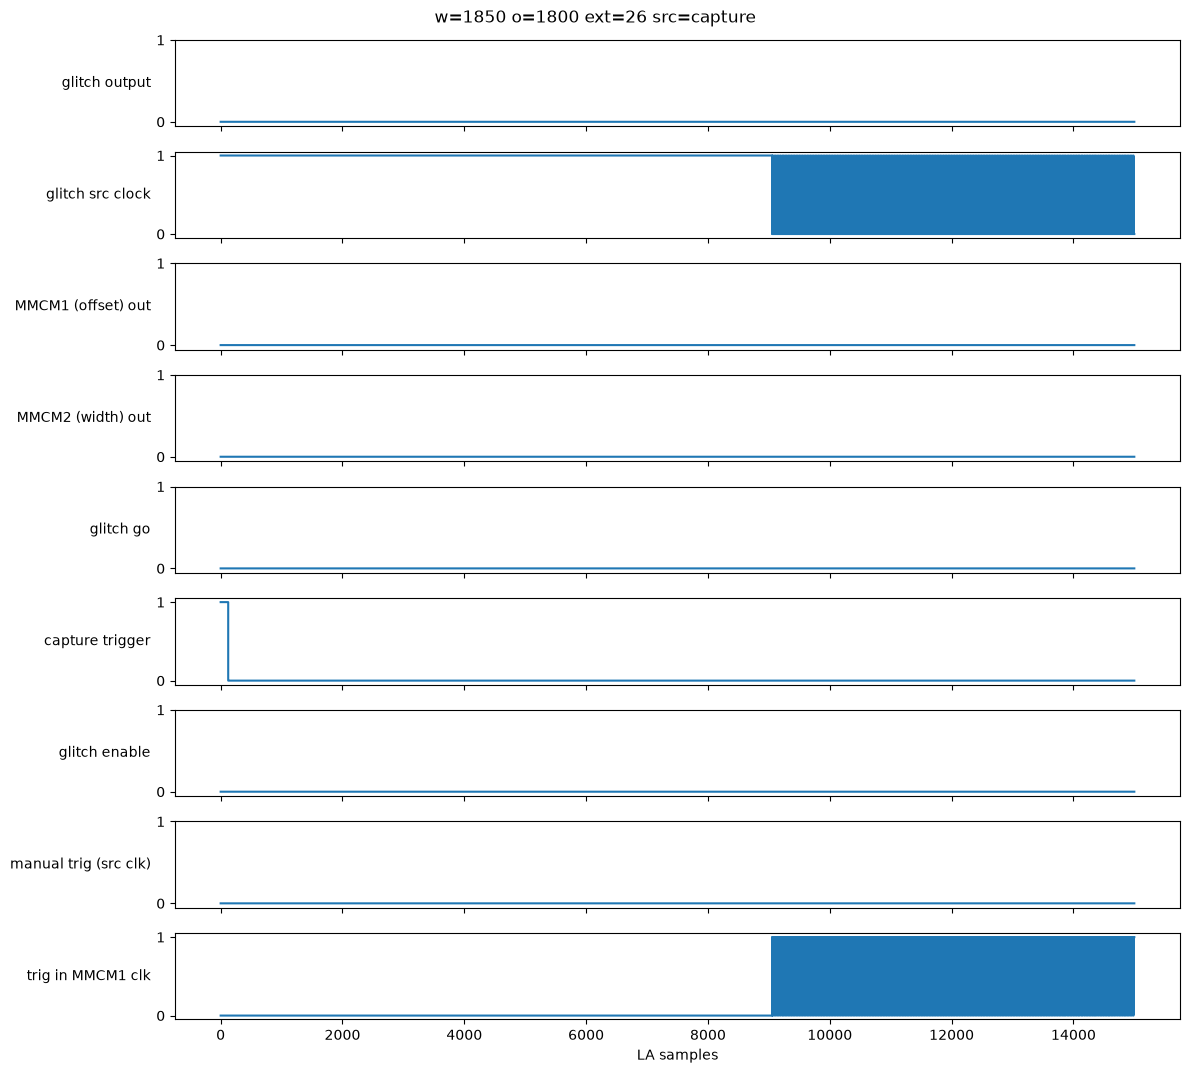

time_axis 1.358002243099103 us


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import struct

NAMES = {
    'glitch': ['glitch output', 'glitch src clock', 'MMCM1 (offset) out',
               'MMCM2 (width) out', 'glitch go', 'capture trigger',
               'glitch enable', 'manual trig (src clk)', 'trig in MMCM1 clk'],
    'CW 20-pin': ['IO1', 'IO2', 'IO3', 'IO4', 'HS1', 'HS2',
                  'AUX MCX', 'TRIG MCX', 'ADC sampling clk'],
}

def calculate_time_axis_seconds_per_dotted_sample(scope):
    f  = scope.LA.sampling_clock_frequency   # Hz, e.g. 7.36e6 in your printout
    ds = scope.LA.downsample
    dt = ds / f                              # seconds per plotted sample (see note below)
    return dt

def calculate_print_on_time_io4(scope, raw):
    f  = scope.LA.sampling_clock_frequency
    dt = scope.LA.downsample / f        # see the note on downsample below
    io4 = np.asarray(scope.LA.extract(raw, 3)).astype(int)   # 'CW 20-pin' group, bit 3 = IO4

    d = np.diff(io4)
    rising  = np.flatnonzero(d ==  1) + 1    # index of first high sample
    falling = np.flatnonzero(d == -1) + 1    # index of first low sample after the high

    if len(rising) == 0:
        print("no rising edge in window (line stayed constant)")
    else:
        r = rising[0]
        fl = falling[falling > r]
        if len(fl) == 0:
            print(f"rising edge at {r*dt*1e6:.2f} us, but no falling edge in the window: "
                  f"high time > {(len(io4)-r)*dt*1e6:.2f} us")
        else:
            high_samples = fl[0] - r
            print(f"IO4 high for {high_samples} samples = {high_samples*dt*1e6:.2f} us "  f"(+/- {dt*1e6:.2f} us)")

def plot_la(raw, group, title="", hide_constant=True):
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = np.asarray(scope.LA.extract(raw, i))
        except Exception as ex:
            print(f"extract({i}) failed: {type(ex).__name__}: {ex}")
            break

    # show what was captured, so a flat plot isn't a mystery
    if hide_constant == True:
        for i, s in sigs.items():
            print(f"{NAMES[group][i]:24} samples={len(s)} min={s.min()} max={s.max()} "
                  f"transitions={int(np.count_nonzero(np.diff(s)))}")

    if not sigs:
        print("nothing extracted")
        return

    shown = {i: s for i, s in sigs.items() if s.min() != s.max()} if hide_constant else sigs
    if not shown:
        print("all signals constant -> plotting all of them instead")
        shown = sigs

    fig, axes = plt.subplots(len(shown), 1, figsize=(12, 1.1 * len(shown) + 1), sharex=True)
    for ax, (i, s) in zip(np.atleast_1d(axes), shown.items()):
        ax.step(range(len(s)), s, where='post')
        ax.set_ylabel(NAMES[group][i], rotation=0, ha='right', va='center')
        ax.set_yticks([0, 1])
    np.atleast_1d(axes)[-1].set_xlabel("LA samples")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
    
def visualize_glitch(width, offset, ext_offset, group='CW 20-pin', depth=4000, source='capture'):
    scope.glitch.trigger_src = "ext_single"
    scope.glitch.width = width
    scope.glitch.offset = offset
    scope.glitch.ext_offset = ext_offset

    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = depth
    scope.LA.oversampling_factor = 1  # sample 4x faster than the clock
    scope.LA.trigger_source = source
    
    reboot_flush()
    target.flush()
    scope.LA.arm()          # needed in your build
    scope.arm()
    target.simpleserial_write("g", bytearray([]))
    timed_out = scope.capture()
    scope.io.vglitch_reset()

    if timed_out or scope.LA.fifo_empty():
        print("no data", timed_out, scope.LA.errors)
        scope.LA.enabled = False
        return

    raw = scope.LA.read_capture_data()
    scope.LA.enabled = False
    plot_la(raw, group, f"w={width} o={offset} ext={ext_offset} src={source}", hide_constant=False)   

    print("time_axis", calculate_time_axis_seconds_per_dotted_sample(scope)*1e6, "us")
    if group=='CW 20-pin':
        calculate_print_on_time_io4(scope, raw)


scope.trigger.triggers = "tio2"   # tio4==trigger tio1==tx tio2==rx SAM4S perspective
scope.glitch.width = 1850
scope.glitch.offset = 1800
scope.glitch.ext_offset = 26

depth=15000
scope.LA.downsample = 10


w, o, e = scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset
visualize_glitch(w, o, e, group='CW 20-pin', depth=depth)
visualize_glitch(w, o, e, group='glitch', depth=depth)

In [98]:
print(scope.io)        # tio1..tio4 modes, hs2 mode, glitch output, etc.
print(scope.clock)     # clock source and frequency settings
print(scope.trigger)   # which pins the trigger listens to
print(scope.glitch)    # glitch module settings
print(scope.adc)       # ADC clock source and sampling settings

tio1            = serial_rx
tio2            = serial_tx
tio3            = high_z
tio4            = high_z
pdid            = high_z
pdic            = high_z
nrst            = high_z
glitch_hp       = True
glitch_lp       = False
extclk_src      = hs1
hs2             = clkgen
target_pwr      = True
tio_states      = (1, 1, 1, 0)
cdc_settings    = [0, 0, 0, 0]
aux_io_mcx      = high_z
glitch_trig_mcx = trigger

clkgen_src             = system
clkgen_freq            = 7363636.363636363
adc_mul                = 4
adc_freq               = 29454545.454545453
adc_rate               = 29454545.454545453
freq_ctr               = 0
freq_ctr_src           = extclk
clkgen_locked          = True
adc_phase              = 0.0
extclk_monitor_enabled = False
extclk_error           = False
extclk_tolerance       = 1144409.1796875

sequencer_enabled = False
module            = basic
triggers          = tio4

enabled           = True
num_glitches      = 1
clk_src           = pll
mmcm_locked       = True
wi

In [99]:
print(scope.io.hs2, scope.clock.clkgen_src, scope.clock.clkgen_freq, scope.clock.adc_freq)

clkgen system 7363636.363636363 29454545.454545453


In [37]:
import inspect

print(scope.fw_version)   # should print a sensible version
print(PLATFORM)           # confirm it matches your target
print(prog)               # confirm the programmer class
print("scope._is_husky: ", scope._is_husky)
print("target.baud ", target.baud) # 230400
print("scope.clock.clkgen_freq ", scope.clock.clkgen_freq)  # 7363636.363636363
print("SS_VER ", SS_VER)

{'major': 1, 'minor': 2, 'debug': 0}
CW312_SAM4S
<class 'chipwhisperer.capture.api.programmers.SAM4SProgrammer'>
scope._is_husky:  True
target.baud  230400
scope.clock.clkgen_freq  7363636.363636363
SS_VER  SS_VER_2_1


In [63]:
reboot_flush()
scope.arm()
target.simpleserial_write("g", bytearray([]))
scope.capture()
val = target.simpleserial_read_witherrors('r', 4, glitch_timeout=10)#For loop check
valid = val['valid']
if valid:
    response = val['payload']
    raw_serial = val['full_response']
    error_code = val['rv']

print(val)

{'valid': True, 'payload': CWbytearray(b'c4 09 00 00'), 'full_response': CWbytearray(b'00 72 04 c4 09 00 00 15 00'), 'rv': bytearray(b'\x00')}


In [76]:
#gc = cw.GlitchController(groups=["success", "reset", "normal"], parameters=["width", "offset", "ext_offset", "tries"])
gc.display_stats()

IntText(value=0, description='success count:', disabled=True)

IntText(value=0, description='reset count:', disabled=True)

IntText(value=0, description='normal count:', disabled=True)

FloatSlider(value=1850.0, continuous_update=False, description='width setting:', disabled=True, max=2100.0, mi…

FloatSlider(value=1800.0, continuous_update=False, description='offset setting:', disabled=True, max=3000.0, m…

FloatSlider(value=10.0, continuous_update=False, description='ext_offset setting:', disabled=True, max=10.0, m…

FloatSlider(value=1.0, continuous_update=False, description='tries setting:', disabled=True, max=1.0, min=1.0,…

In [6]:
gc.display_stats()
gc.glitch_plot(plotdots={"success":"+g", "reset":"xr", "normal":None})

IntText(value=0, description='success count:', disabled=True)

IntText(value=0, description='reset count:', disabled=True)

IntText(value=0, description='normal count:', disabled=True)

FloatSlider(value=1850.0, continuous_update=False, description='width setting:', disabled=True, max=3000.0, mi…

FloatSlider(value=1800.0, continuous_update=False, description='offset setting:', disabled=True, max=3000.0, m…

FloatSlider(value=10.0, continuous_update=False, description='ext_offset setting:', disabled=True, max=50.0, m…

FloatSlider(value=1.0, continuous_update=False, description='tries setting:', disabled=True, max=1.0, min=1.0,…

:DynamicMap   []
   :Overlay
      .Points.I  :Points   [width,offset]
      .Points.II :Points   [width,offset]

Next, we'll setup the glitch. The main differences here compared to clock glitching is the use of `scope.io.glitch_lp/hp`, which activates the transistors used for voltage, and `scope.glitch.output = 'glitch_only'`, which sends the glitch output to the transistors instead of xoring it with the clock like with clock glitching.

In [7]:
# from solution
num_tries = 1 # increase to get better glitch stats
gc.set_range("tries", 1, num_tries)

scope.trigger.triggers = "tio4"   # tio4==trigger tio1==tx tio2==rx SAM4S perspective

scope.glitch.output = "glitch_only" # glitch_out = clk ^ glitch
scope.glitch.trigger_src = "ext_single" # glitch only after scope.arm() called

# trigger high time == 7310.13 us

# reset width > 2150
#gc.set_range("width", 1850, 3000)
#gc.set_range("offset", 1800, 3000)
#gc.set_step("ext_offset", 1)
#gc.set_range("ext_offset", 10, 50)
gc.set_range("ext_offset", 10, 10)
gc.set_range("width", 1850, 2100)
gc.set_range("offset", 1800, 3000)
gc.set_global_step([50]) # reduce to fine tune glitching

scope.glitch.repeat = 1
scope.adc.lo_gain_errors_disabled = True
scope.adc.clip_errors_disabled = True

scope.glitch.enabled = True
scope.glitch.clk_src = "pll"
scope.io.glitch_hp = False
scope.io.glitch_hp = True
scope.io.glitch_lp = False
scope.io.glitch_lp = False


gc.set_step("tries", 1)

In [40]:
import math

def glitch_settings(delay_ns, width_ns):
    f_clk  = scope.clock.clkgen_freq
    T_clk  = 1 / f_clk
    steps  = scope.glitch.phase_shift_steps
    t_step = T_clk / steps

    delay = delay_ns * 1e-9
    ext_offset = int(delay // T_clk)                    # whole cycles
    offset     = round((delay - ext_offset * T_clk) / t_step)   # remainder in steps
    width      = round(width_ns * 1e-9 / t_step)

    print(f"ext_offset = {ext_offset}, offset = {offset}, width = {width}")
    print(f"offset max (one period) = {steps}")
    return ext_offset, offset, width

# example: glitch 3.6 us after the first clock edge, 40 ns long
glitch_settings(3600, 40)

ext_offset = 26, offset = 2338, width = 1353
offset max (one period) = 4592


(26, 2338, 1353)

In [52]:
print("glitch MMCM locked:", scope.glitch.mmcm_locked)
print("PLL locked:        ", scope.clock.pll.pll_locked)
print("ADC locked:        ", scope.clock.adc_locked)
print("clkgen freq:       ", scope.clock.clkgen_freq)
print("adc freq:          ", scope.clock.adc_freq)
print("ADC errors:        ", scope.adc.errors)
print("ADC state:         ", scope.adc.state)
print("LA errors:         ", scope.LA.errors)
print("scope errors:      ", scope.errors)

glitch MMCM locked: True
PLL locked:         True
ADC locked:         True
clkgen freq:        7363636.363636363
adc freq:           29454545.454545453
ADC errors:         segmenting error, trigger too soon error, 
ADC state:          True
LA errors:          None
scope errors:       sam_errors      = False
sam_led_setting = Default
XADC errors     = False
ADC errors      = segmenting error, trigger too soon error, 
extclk error    = False
trace errors    = False



In [67]:
#print(scope.glitch)                                   # may list the phase-shift steps or VCO info
#print([a for a in dir(scope.glitch) if any(k in a.lower() for k in ('mmcm', 'phase', 'step', 'vco', 'clk'))])
#print(scope.glitch.clk_src, scope.clock.clkgen_freq)  # source clock for the glitch module

def calculate_glitch_timing(scope, debug=False):

    f_clk = scope.clock.clkgen_freq      
    T_clk = 1 / f_clk
    steps  = scope.glitch.phase_shift_steps
    f_tgt  = scope.clock.clkgen_freq          # target clock frequency
    t_step = 1 / (f_tgt * steps)              # seconds per width/offset increment
    vco   = scope.clock.fpga_vco_freq     # from the phase_shift_steps docstring
    glitch_start  = scope.glitch.ext_offset * T_clk + scope.glitch.offset * t_step   # (after the first clock edge)
    glitch_length = scope.glitch.width * t_step

    if debug == True:
        print("scope.glitch.clk_src ", scope.glitch.clk_src)          # which clock the glitch module uses
        print("scope.clock.clkgen_freq ", scope.clock.clkgen_freq)       # clock the scope generates for the target (Hz)
    
        print(f"T_clk = {T_clk*1e9:.1f} ns")
    
        print(f"f_clk  = {f_clk/1e6:.3f} MHz,  T_clk = {1e9/f_clk:.1f} ns")
        print(f"steps per period = {steps}")
        print(f"t_step = {1e12/(f_clk*steps):.1f} ps")
        print(f"VCO = {vco/1e6:.1f} MHz, 56 * VCO / f_clk = {56*vco/f_clk:.0f}")
        print(f"target clock: {f_tgt/1e6:.3f} MHz, period {1e9/f_tgt:.1f} ns")
        print(f"one step = {t_step*1e12:.1f} ps")
        print(f"width  {scope.glitch.width} = {scope.glitch.width*t_step*1e9:.1f} ns")
        print(f"offset {scope.glitch.offset} = {scope.glitch.offset*t_step*1e9:.1f} ns")
        print(f"glitch_start {glitch_start*1e6:.1f}us")
        print(f"glitch_length {glitch_length*1e9:.1f}ns")

    return glitch_start, glitch_length

scope.glitch.width = 1850
scope.glitch.offset = 1800
scope.glitch.ext_offset = 50
start, length = calculate_glitch_timing(scope)
print(f"glitch start {start*1e6:.1f}us length {length*1e9:.1f}ns")


glitch start 6.8us length 54.7ns


Some tips for finding good glitches:

1. There's a lot of stuff fighting our glitch this time - unlike the clock line, the Vcc rail isn't supposed to oscillate! As such shorter glitches will have no effect. Often, good widths will be just below when the target starts consistantly crashing, so a good strategy is to find the minimum width where crashes always happen, then backing the width off a bit.
1. The repeat parameter behaves very differently than with voltage glitching - at the boosted clock rate, the Vcc often won't recover before the next glitch. Try different repeat values as well.
1. We've built in a success/reset measurement into the glitch loop. Once you've found some glitch spots, this will help you evaluate which ones are best for your target.

It can take a very long time to do go through the full search space, so you may want to stop after you get a certain number of succeses. By default here, it will be 1, but you may want to change it to 10, 20, or go even higher.

In [8]:
MAX_SUCCESSES = 1

In [18]:
# only diagnostic
print(scope.glitch.enabled)
print(scope.glitch.mmcm_locked)
print(scope.glitch.state)   # on some versions

True
True
idle


In [19]:
# only diagnostic
for i, s in enumerate(gc.glitch_values()):
    print(i, s)
    if i > 10: break

0 [1850, 1800, 10, 1]
1 [1850, 1800, 11, 1]
2 [1850, 1800, 12, 1]
3 [1850, 1800, 13, 1]
4 [1850, 1800, 14, 1]
5 [1850, 1800, 15, 1]
6 [1850, 1800, 16, 1]
7 [1850, 1800, 17, 1]
8 [1850, 1800, 18, 1]
9 [1850, 1800, 19, 1]
10 [1850, 1800, 20, 1]
11 [1850, 1800, 21, 1]


In [44]:
import inspect
#print(inspect.getsource(gc.glitch_values))   # shows exactly what's yielded
#help(gc.glitch_values)                       # docstring
#print(inspect.getsource(type(gc)))

In [ ]:
# from solution
import struct

def wait_for_mmcm(timeout=2.0):
    t0 = time.time()
    while not scope.glitch.mmcm_locked:
        if time.time() - t0 > timeout:
            raise RuntimeError("MMCM did not lock")
        time.sleep(0.01)
        
#disable logging
cw.set_all_log_levels(cw.logging.CRITICAL)

scope.adc.timeout = 0.5

reboot_flush()
loff = scope.glitch.offset
lwid = scope.glitch.width
total_successes = 0
successes = 0
resets = 0
first = True
for glitch_setting in gc.glitch_values():
    #wait_for_mmcm()
    scope.glitch.offset = glitch_setting[1]
    scope.glitch.width = glitch_setting[0]
    scope.glitch.ext_offset = glitch_setting[2]
    #print(scope.glitch.ext_offset)
    if glitch_setting[3] == 1:
        total_successes += successes
        if (successes > 0):
            print("successes = {}, resets = {}, offset = {}, width = {}, ext_offset = {}".format(successes, resets, scope.glitch.offset, scope.glitch.width, scope.glitch.ext_offset))
            total_successes += successes
        successes = 0
        resets = 0
        #if total_successes > MAX_SUCCESSES:
        #    break
    target.flush()
    if scope.adc.state:
        # can detect crash here (fast) before timing out (slow)
        #print("Trigger still high!")
        gc.add("reset")

        #Device is slow to boot?
        reboot_flush()
        resets += 1

    scope.arm()

    #Do glitch loop
    target.simpleserial_write("g", bytearray([]))

    ret = scope.capture()

    scope.io.vglitch_reset()
        
    if ret:
        #print('Timeout - no trigger')
        gc.add("reset")
        resets += 1

        #Device is slow to boot?
        reboot_flush()

    else:
        if first ==True:
            #visualize_glitch(width=scope.glitch.width, offset=scope.glitch.offset, ext_offset=scope.glitch.ext_offset)
            first=False
        
        val = target.simpleserial_read_witherrors('r', 4, glitch_timeout=10, timeout=50)#For loop check
        if val['valid'] is False:
            gc.add("reset")
            reboot_flush()
            resets += 1
            print(val)
        else:
            gcnt = struct.unpack("<I", val['payload'])[0]

            if gcnt != 2500: #for loop check
                gc.add("success")
                print((scope.glitch.width, scope.glitch.offset, scope.glitch.ext_offset))
                successes += 1
            else:
                gc.add("normal")

print("Done glitching")
#enable logging
cw.set_all_log_levels(cw.logging.WARNING)

With that done, let's print our results. You'll likely want to ignore the "tries" and "ext_offset" parameters:

In [35]:
results = gc.calc(ignore_params=["tries", "ext_offset"], sort="success_rate")
results

[((3000, 3000),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2950),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2900),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2850),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2800),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2750),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,
   'reset_rate': 0.0,
   'normal': 41,
   'normal_rate': 1.0}),
 ((3000, 2700),
  {'total': 41,
   'success': 0,
   'success_rate': 0.0,
   'reset': 0,


In [49]:
scope.dis()
target.dis()